# CMI Problematic Internet Use — Data, Veracity & Velocity Exploration

Exploratory notebook for `train.csv`, `data_dictionary.csv`, and `series_train.parquet`.
Structured around:
1. **Overview & Target Structure** (`sii`, `PCIAT_Total`, instrument groups)
2. **Veracity** (missingness, label consistency, physiological sanity & outliers, actigraphy sensor quality)
3. **Velocity** (seasonal assessment lags, actigraphy sampling cadence, `relative_date_PCIAT` timing, diurnal & weekday/weekend activity profiles)

## 1. Setup & Configuration

In [1]:
import os
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
%matplotlib inline

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_style('whitegrid')

current_dir = os.getcwd()
workspace_root = Path(current_dir).parent if os.path.basename(current_dir).lower() == 'notebooks' else Path(current_dir)
data_root = workspace_root / 'Data'

print(f'Workspace root: {workspace_root}')
print(f'Data root:      {data_root} (exists={data_root.exists()})')

Workspace root: c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use
Data root:      c:\Users\maran\OneDrive\Documents\Git Profile\Data-Projects\cmi_internet_use\Data (exists=True)


In [2]:
max_parquet_sample = 150    # set to None to scan all actigraphy participants
random_state = 42

## 2. Load Training Data

In [3]:
train_df = pd.read_csv(data_root / 'train.csv')
test_df = pd.read_csv(data_root / 'test.csv')
data_dict_df = pd.read_csv(data_root / 'data_dictionary.csv')

train_series_dirs = sorted(glob.glob(str(data_root / 'series_train.parquet' / 'id=*')))
train_series_ids = {os.path.basename(p).replace('id=', '') for p in train_series_dirs}

test_series_dirs = sorted(glob.glob(str(data_root / 'series_test.parquet' / 'id=*')))
test_series_ids = {os.path.basename(p).replace('id=', '') for p in test_series_dirs}

train_df['has_actigraphy'] = train_df['id'].isin(train_series_ids)
test_df['has_actigraphy'] = test_df['id'].isin(test_series_ids)

print(f'train.csv: {train_df.shape[0]:,} rows x {train_df.shape[1]} cols | unique ids: {train_df["id"].nunique():,}')
print(f'test.csv:  {test_df.shape[0]:,} rows x {test_df.shape[1]} cols | unique ids: {test_df["id"].nunique():,}')
print(f'Actigraphy folders — train: {len(train_series_ids):,} | test: {len(test_series_ids):,}')

train.csv: 3,960 rows x 83 cols | unique ids: 3,960
test.csv:  20 rows x 60 cols | unique ids: 20
Actigraphy folders — train: 996 | test: 2


In [4]:
train_only_cols = sorted(set(train_df.columns) - set(test_df.columns))
print(f'Columns in train.csv but NOT in test.csv ({len(train_only_cols)}):')
print(train_only_cols)

Columns in train.csv but NOT in test.csv (23):
['PCIAT-PCIAT_01', 'PCIAT-PCIAT_02', 'PCIAT-PCIAT_03', 'PCIAT-PCIAT_04', 'PCIAT-PCIAT_05', 'PCIAT-PCIAT_06', 'PCIAT-PCIAT_07', 'PCIAT-PCIAT_08', 'PCIAT-PCIAT_09', 'PCIAT-PCIAT_10', 'PCIAT-PCIAT_11', 'PCIAT-PCIAT_12', 'PCIAT-PCIAT_13', 'PCIAT-PCIAT_14', 'PCIAT-PCIAT_15', 'PCIAT-PCIAT_16', 'PCIAT-PCIAT_17', 'PCIAT-PCIAT_18', 'PCIAT-PCIAT_19', 'PCIAT-PCIAT_20', 'PCIAT-PCIAT_Total', 'PCIAT-Season', 'sii']


## 3. Overview & Target Structure

In [5]:
sii_counts = train_df['sii'].value_counts(dropna=False).sort_index()
sii_pct = (train_df['sii'].value_counts(dropna=False, normalize=True).sort_index() * 100).round(2)
sii_summary = pd.DataFrame({'count': sii_counts, 'pct': sii_pct})
display(sii_summary)

labeled_df = train_df[train_df['sii'].notna()].copy()
print(f'Labeled rows: {len(labeled_df):,} / {len(train_df):,} ({len(labeled_df) / len(train_df) * 100:.1f}%)')
print(f'Labeled + actigraphy: {labeled_df["has_actigraphy"].sum():,} / {len(labeled_df):,}')

,count,pct
sii,,
0.0,1594,40.25
1.0,730,18.43
2.0,378,9.55
3.0,34,0.86
NaN,1224,30.91


Labeled rows: 2,736 / 3,960 (69.1%)
Labeled + actigraphy: 996 / 2,736


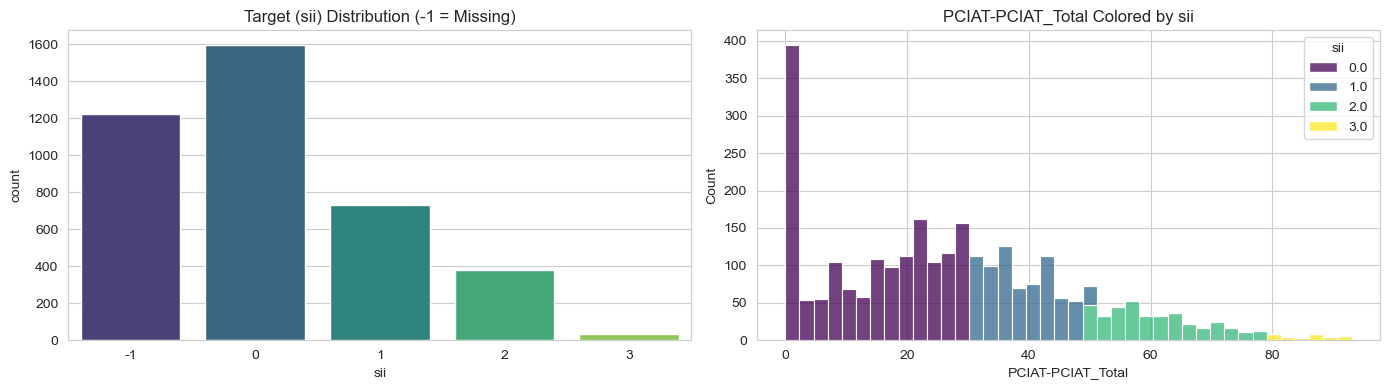

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sii_plot = train_df['sii'].fillna(-1).astype(int)
sns.countplot(x=sii_plot, ax=axes[0], palette='viridis')
axes[0].set_title('Target (sii) Distribution (-1 = Missing)')
axes[0].set_xlabel('sii')

sns.histplot(data=labeled_df, x='PCIAT-PCIAT_Total', hue='sii', bins=40, multiple='stack', ax=axes[1], palette='viridis')
axes[1].set_title('PCIAT-PCIAT_Total Colored by sii')
plt.tight_layout()
plt.show()

## 4. Data Veracity (Tabular)
Checking missingness by instrument, train-vs-test missingness drift, `PCIAT_Total` vs `sii` label consistency, and physiological plausibility.

In [7]:
instrument_prefixes = [
    'Basic_Demos', 'CGAS', 'Physical', 'Fitness_Endurance',
    'FGC', 'BIA', 'PAQ_A', 'PAQ_C', 'PCIAT', 'SDS', 'PreInt_EduHx'
]

instrument_rows = []
for prefix in instrument_prefixes:
    cols = [c for c in train_df.columns if c.startswith(prefix + '-')]
    train_miss = train_df[cols].isna().mean().mean() * 100
    train_any_present = train_df[cols].notna().any(axis=1).mean() * 100
    test_cols = [c for c in cols if c in test_df.columns]
    test_miss = test_df[test_cols].isna().mean().mean() * 100 if test_cols else np.nan
    instrument_rows.append({
        'instrument': prefix,
        'n_cols': len(cols),
        'train_mean_missing_%': round(train_miss, 2),
        'train_any_present_%': round(train_any_present, 2),
        'test_mean_missing_%': round(test_miss, 2) if pd.notna(test_miss) else np.nan
    })

instrument_missing_df = pd.DataFrame(instrument_rows)
display(instrument_missing_df)

,instrument,n_cols,train_mean_missing_%,train_any_present_%,test_mean_missing_%
0,Basic_Demos,3,0.00,100.00,0.00
1,CGAS,2,37.17,64.52,55.00
2,Physical,8,29.90,83.59,42.50
3,Fitness_Endurance,4,77.71,33.03,83.75
4,FGC,15,48.55,84.49,44.33
5,BIA,17,49.49,54.17,60.00
6,PAQ_A,2,88.01,11.99,95.00
7,PAQ_C,2,56.54,43.46,55.00
8,PCIAT,22,31.03,69.09,NaN
9,SDS,3,34.07,66.11,50.00


In [8]:
# Verify PCIAT_Total == sum(PCIAT_01..20) and sii bucket consistency
pciat_item_cols = [f'PCIAT-PCIAT_{i:02d}' for i in range(1, 21)]
pciat_check = labeled_df[['id', 'sii', 'PCIAT-PCIAT_Total'] + pciat_item_cols].copy()
pciat_check['items_answered'] = pciat_check[pciat_item_cols].notna().sum(axis=1)
pciat_check['items_sum'] = pciat_check[pciat_item_cols].sum(axis=1)
pciat_check['sum_diff'] = pciat_check['PCIAT-PCIAT_Total'] - pciat_check['items_sum']

expected_sii = pd.cut(
    pciat_check['PCIAT-PCIAT_Total'],
    bins=[-1, 30, 49, 79, 200],
    labels=[0, 1, 2, 3]
).astype(float)
sii_mismatch = (pciat_check['sii'] != expected_sii).sum()

print(f'Duplicate participant IDs in train.csv: {train_df["id"].duplicated().sum()}')
print(f'Rows with partial PCIAT (<20 items answered) among labeled: {(pciat_check["items_answered"] < 20).sum()}')
print(f'Rows where PCIAT_Total != sum(PCIAT_01..20): {(pciat_check["sum_diff"] != 0).sum()}')
print(f'Rows where sii != official PCIAT_Total bucket: {sii_mismatch}')

Duplicate participant IDs in train.csv: 0
Rows with partial PCIAT (<20 items answered) among labeled: 65
Rows where PCIAT_Total != sum(PCIAT_01..20): 0
Rows where sii != official PCIAT_Total bucket: 0


In [9]:
# Physiological & measurement veracity checks
veracity_checks = {
    'Age < 5 or > 22': ((train_df['Basic_Demos-Age'] < 5) | (train_df['Basic_Demos-Age'] > 22)).sum(),
    'BMI <= 10 or >= 60': ((train_df['Physical-BMI'] <= 10) | (train_df['Physical-BMI'] >= 60)).sum(),
    'HeartRate < 40 or > 180': ((train_df['Physical-HeartRate'] < 40) | (train_df['Physical-HeartRate'] > 180)).sum(),
    'Diastolic >= Systolic BP': (train_df['Physical-Diastolic_BP'] >= train_df['Physical-Systolic_BP']).sum(),
    'BIA_Fat <= 0 or >= 70': ((train_df['BIA-BIA_Fat'] <= 0) | (train_df['BIA-BIA_Fat'] >= 70)).sum(),
    'CGAS_Score < 1 or > 100': ((train_df['CGAS-CGAS_Score'] < 1) | (train_df['CGAS-CGAS_Score'] > 100)).sum(),
    'Both PAQ_A and PAQ_C present': (train_df['PAQ_A-PAQ_A_Total'].notna() & train_df['PAQ_C-PAQ_C_Total'].notna()).sum(),
    'Neither PAQ_A nor PAQ_C present': (train_df['PAQ_A-PAQ_A_Total'].isna() & train_df['PAQ_C-PAQ_C_Total'].isna()).sum(),
}
display(pd.Series(veracity_checks, name='flagged_row_count').to_frame())

,flagged_row_count
Age < 5 or > 22,0
BMI <= 10 or >= 60,10
HeartRate < 40 or > 180,4
Diastolic >= Systolic BP,5
BIA_Fat <= 0 or >= 70,111
CGAS_Score < 1 or > 100,1
Both PAQ_A and PAQ_C present,1
Neither PAQ_A nor PAQ_C present,1765


In [10]:
# Check Physical-BMI vs Weight/Height consistency (BMI = 703 * weight_lbs / height_in^2)
bmi_calc = 703.0 * train_df['Physical-Weight'] / (train_df['Physical-Height'] ** 2)
bmi_diff = (train_df['Physical-BMI'] - bmi_calc).abs()
print('Absolute difference between reported Physical-BMI and 703 * Weight / Height^2:')
display(bmi_diff.describe(percentiles=[0.5, 0.9, 0.99]).round(4).to_frame())

Absolute difference between reported Physical-BMI and 703 * Weight / Height^2:


,0
count,3022.0000
mean,0.0000
std,0.0003
min,0.0000
50%,0.0000
90%,0.0000
99%,0.0018
max,0.0047


## 5. Data Velocity & Assessment Timing (Tabular)
Examining seasonal cohort flow and whether instruments for the same participant were collected in the same season or lagged across seasons.

,season_col,n_present,same_as_enroll_%
0,Basic_Demos-Enroll_Season,3960,100.00
1,CGAS-Season,2555,9.00
2,Physical-Season,3310,47.64
3,Fitness_Endurance-Season,1308,33.41
4,FGC-Season,3346,46.20
5,BIA-Season,2145,39.02
6,PAQ_A-Season,475,61.26
7,PAQ_C-Season,1721,60.31
8,PCIAT-Season,2736,39.25
9,SDS-Season,2618,43.01


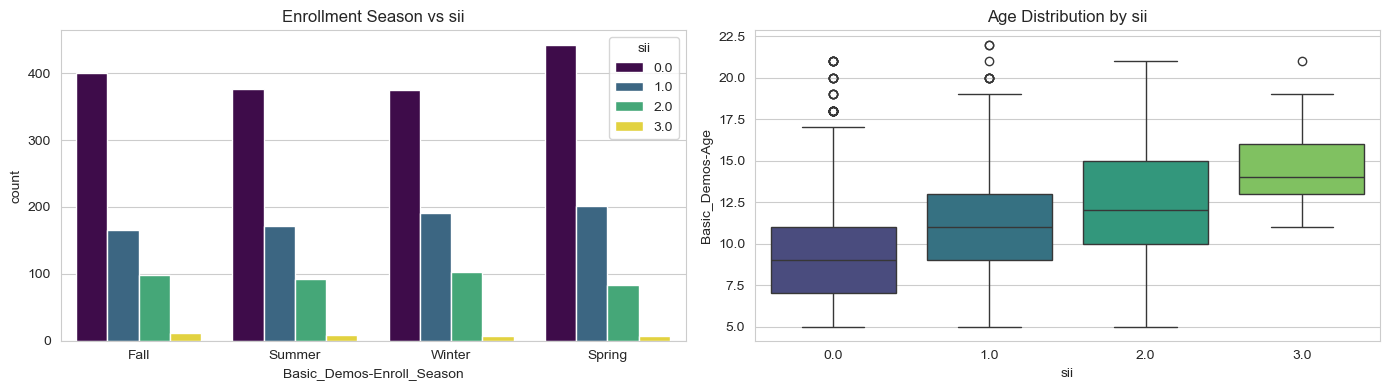

In [11]:
season_cols = [c for c in train_df.columns if c.endswith('-Season') or c == 'Basic_Demos-Enroll_Season']
season_match_rows = []
for col in season_cols:
    both_present = train_df['Basic_Demos-Enroll_Season'].notna() & train_df[col].notna()
    same_rate = (train_df.loc[both_present, 'Basic_Demos-Enroll_Season'] == train_df.loc[both_present, col]).mean() * 100
    season_match_rows.append({
        'season_col': col,
        'n_present': int(both_present.sum()),
        'same_as_enroll_%': round(same_rate, 2)
    })
display(pd.DataFrame(season_match_rows))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=labeled_df, x='Basic_Demos-Enroll_Season', hue='sii', ax=axes[0], palette='viridis')
axes[0].set_title('Enrollment Season vs sii')

sns.boxplot(data=labeled_df, x='sii', y='Basic_Demos-Age', ax=axes[1], palette='viridis')
axes[1].set_title('Age Distribution by sii')
plt.tight_layout()
plt.show()

## 6. Actigraphy Coverage, Veracity & Velocity (`series_train.parquet`)
Scanning participant parquet files to measure:
- **Coverage:** Actigraphy availability vs `sii` and `Age`
- **Veracity:** `non-wear_flag`, vector magnitude `sqrt(X^2+Y^2+Z^2)`, `enmo` / `anglez` bounds, `battery_voltage` drops
- **Velocity:** Sampling cadence (`time_of_day` step delta), wear duration (days), `relative_date_PCIAT` lag, and circadian activity rhythm

In [12]:
# Actigraphy coverage vs sii
act_cov = train_df.groupby(train_df['sii'].fillna(-1).astype(int)).agg(
    total_subjects=('id', 'count'),
    with_actigraphy=('has_actigraphy', 'sum'),
    actigraphy_pct=('has_actigraphy', lambda s: round(s.mean() * 100, 2))
)
display(act_cov)

,total_subjects,with_actigraphy,actigraphy_pct
sii,,,
-1,1224,0,0.00
0,1594,583,36.57
1,730,266,36.44
2,378,137,36.24
3,34,10,29.41


In [13]:
rng = np.random.default_rng(random_state)
sample_dirs = train_series_dirs if max_parquet_sample is None else list(rng.choice(train_series_dirs, size=min(max_parquet_sample, len(train_series_dirs)), replace=False))

sii_lookup = train_df.set_index('id')['sii'].to_dict()
summary_records = []
hourly_records = []

for p_dir in sample_dirs:
    pid = os.path.basename(p_dir).replace('id=', '')
    pq_files = glob.glob(os.path.join(p_dir, '*.parquet'))
    if not pq_files:
        continue
    sdf = pd.read_parquet(pq_files[0])
    if sdf.empty:
        continue

    vec_mag = np.sqrt(sdf['X']**2 + sdf['Y']**2 + sdf['Z']**2)
    tod_diff_s = sdf['time_of_day'].diff() / 1e9
    valid_diff_s = tod_diff_s[(tod_diff_s > 0) & (tod_diff_s < 3600)]
    step_diff = sdf['step'].diff()

    wear_mask = sdf['non-wear_flag'] == 0
    wear_df = sdf[wear_mask]

    summary_records.append({
        'id': pid,
        'sii': sii_lookup.get(pid, np.nan),
        'n_rows': len(sdf),
        'median_dt_s': float(valid_diff_s.median()) if len(valid_diff_s) else np.nan,
        'step_gaps': int((step_diff > 1).sum()),
        'span_days_rel': float(sdf['relative_date_PCIAT'].max() - sdf['relative_date_PCIAT'].min()),
        'rel_date_min': float(sdf['relative_date_PCIAT'].min()),
        'rel_date_max': float(sdf['relative_date_PCIAT'].max()),
        'non_wear_%': float((sdf['non-wear_flag'] != 0).mean() * 100),
        'nan_cells': int(sdf.isna().sum().sum()),
        'vec_mag_median': float(vec_mag.median()),
        'enmo_mean_wear': float(wear_df['enmo'].mean()) if len(wear_df) else np.nan,
        'enmo_p95_wear': float(wear_df['enmo'].quantile(0.95)) if len(wear_df) else np.nan,
        'battery_min': float(sdf['battery_voltage'].min()),
    })

    if len(wear_df) > 0:
        wear_df = wear_df.copy()
        wear_df['hour'] = (wear_df['time_of_day'] // 3_600_000_000_000).astype(int) % 24
        wear_df['is_weekend'] = wear_df['weekday'].isin([6, 7])
        h_agg = wear_df.groupby(['hour', 'is_weekend'])['enmo'].mean().reset_index()
        h_agg['id'] = pid
        h_agg['sii'] = sii_lookup.get(pid, np.nan)
        hourly_records.append(h_agg)

act_summary_df = pd.DataFrame(summary_records)
hourly_df = pd.concat(hourly_records, ignore_index=True) if hourly_records else pd.DataFrame()

print(f'Scanned {len(act_summary_df)} participant parquet files')
display(act_summary_df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(3))

Scanned 150 participant parquet files


,count,mean,std,min,50%,max
sii,150.0,0.560,0.728,0.000,0.000,2.000
n_rows,150.0,313098.773,139724.755,1195.000,381576.000,756212.000
median_dt_s,150.0,5.000,0.000,5.000,5.000,5.000
step_gaps,150.0,0.000,0.000,0.000,0.000,0.000
span_days_rel,150.0,27.387,12.497,1.000,24.000,98.000
rel_date_min,150.0,50.293,80.679,-48.000,21.000,436.000
rel_date_max,150.0,77.680,82.508,-24.000,53.000,458.000
non_wear_%,150.0,19.065,26.204,0.000,4.942,96.639
nan_cells,150.0,0.000,0.000,0.000,0.000,0.000
vec_mag_median,150.0,0.989,0.010,0.951,0.990,1.009


## 7. Quick Visuals: Veracity, Velocity & Diurnal Activity by `sii`

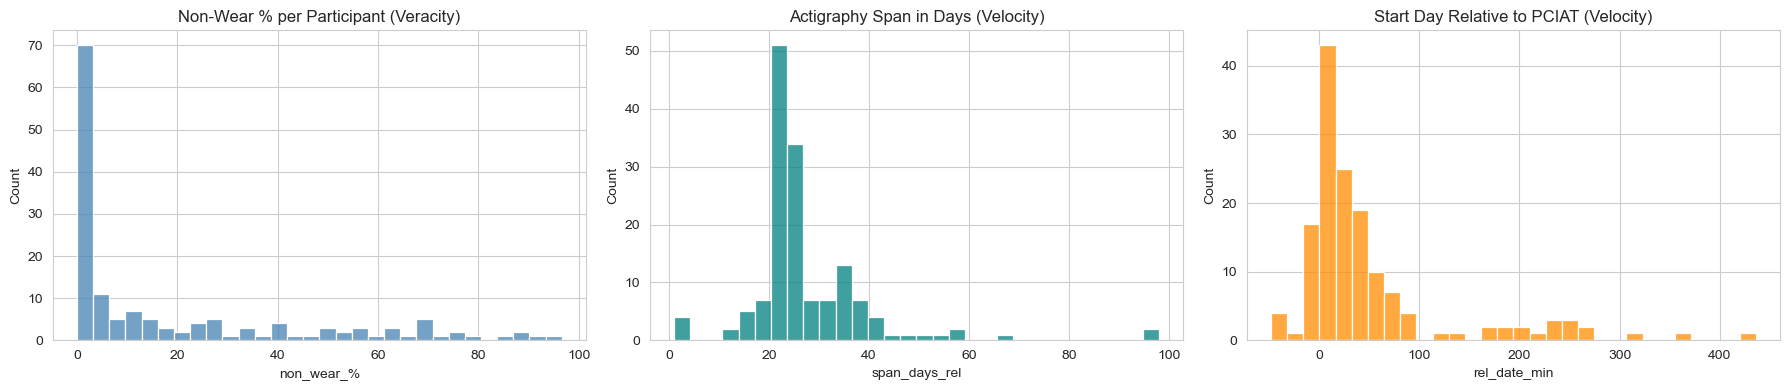

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(act_summary_df['non_wear_%'], bins=30, ax=axes[0], color='steelblue')
axes[0].set_title('Non-Wear % per Participant (Veracity)')

sns.histplot(act_summary_df['span_days_rel'], bins=30, ax=axes[1], color='teal')
axes[1].set_title('Actigraphy Span in Days (Velocity)')

sns.histplot(act_summary_df['rel_date_min'], bins=30, ax=axes[2], color='darkorange')
axes[2].set_title('Start Day Relative to PCIAT (Velocity)')

plt.tight_layout()
plt.show()

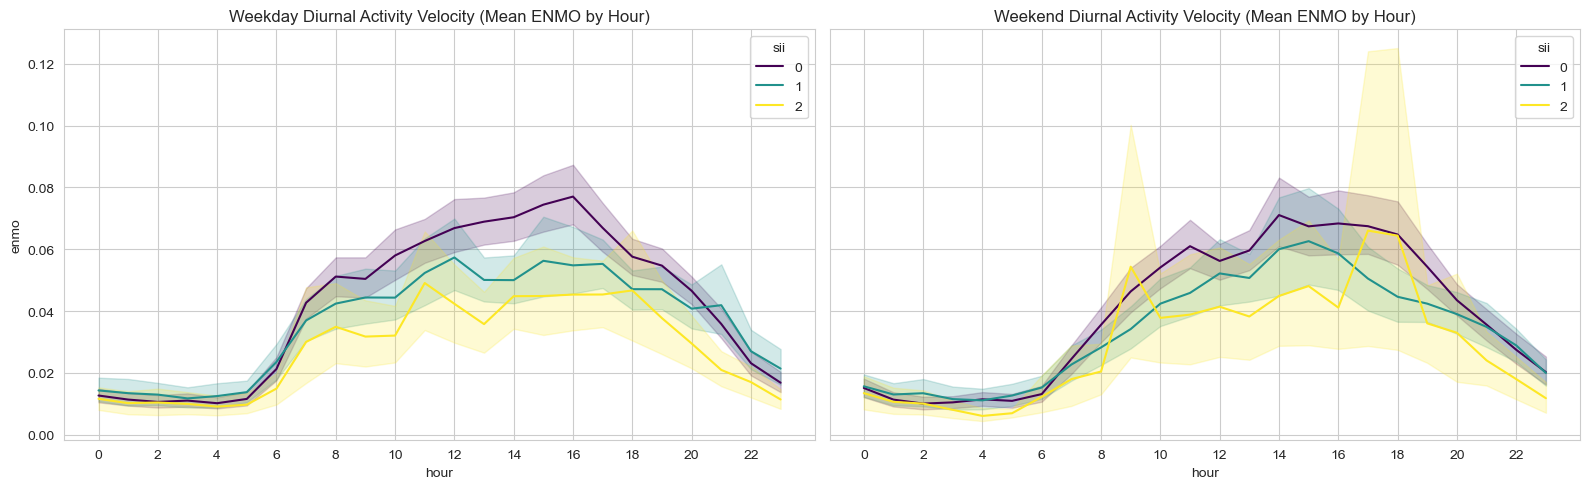

In [15]:
if not hourly_df.empty:
    labeled_hourly = hourly_df[hourly_df['sii'].notna()].copy()
    labeled_hourly['sii'] = labeled_hourly['sii'].astype(int)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

    sns.lineplot(
        data=labeled_hourly[~labeled_hourly['is_weekend']],
        x='hour', y='enmo', hue='sii', palette='viridis', ax=axes[0]
    )
    axes[0].set_title('Weekday Diurnal Activity Velocity (Mean ENMO by Hour)')
    axes[0].set_xticks(range(0, 24, 2))

    sns.lineplot(
        data=labeled_hourly[labeled_hourly['is_weekend']],
        x='hour', y='enmo', hue='sii', palette='viridis', ax=axes[1]
    )
    axes[1].set_title('Weekend Diurnal Activity Velocity (Mean ENMO by Hour)')
    axes[1].set_xticks(range(0, 24, 2))

    plt.tight_layout()
    plt.show()